In [1]:
!pip install root

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.9/247.9 MB 5.4 MB/s eta 0:00:00


In [3]:
import pandas as pd

url="https://opendata.cern.ch/record/302/files/dielectron-Jpsi.csv"

df=pd.read_csv(url)
display(df)

,Run,Event,E1,px1,py1,pz1,pt1,eta1,phi1,Q1,E2,px2,py2,pz2,pt2,eta2,phi2,Q2,M
0,147390,543767492,24.52100,3.897730,-16.162700,-18.02370,16.62600,-0.939585,-1.334160,-1,9.36334,4.20606,-5.503590,-6.30014,6.92679,-0.815936,-0.918244,-1,4.62593
1,147390,551904480,42.83250,-16.472400,4.633090,-39.26600,17.11160,-1.568160,2.867410,1,10.48800,-3.39472,-0.164604,-9.92201,3.39871,-1.792630,-3.093140,-1,2.99060
2,147390,286521299,78.69930,20.734600,-22.760300,72.42670,30.78890,1.590960,-0.831937,-1,19.11860,5.52052,-3.864810,17.89160,6.73891,1.703290,-0.610780,-1,3.56757
3,147390,348830108,35.70960,-12.678300,10.212600,-31.78270,16.27990,-1.422080,2.463500,1,15.74180,-4.55461,2.897110,-14.78730,5.39793,-1.732660,2.575060,-1,3.10446
4,147390,348839604,12.83080,-9.972450,-5.517790,-5.89352,11.39720,-0.496456,-2.636220,-1,20.47440,-18.03860,-2.928180,-9.23231,18.27470,-0.485855,-2.980670,1,4.94889
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,148032,67880204,5.12331,4.858660,0.045153,-1.62470,4.85887,-0.328442,0.009293,1,18.79880,14.18070,-7.550130,-9.76212,16.06540,-0.575372,-0.489248,1,4.87715
1996,148032,69568358,14.14270,4.074400,12.172100,-5.93774,12.83590,-0.447502,1.247790,1,8.33265,1.41249,8.083240,-1.44882,8.20573,-0.175658,1.397800,-1,3.19336
1997,148032,61903342,22.30070,0.382424,12.597800,18.39760,12.60360,1.172200,1.540450,-1,7.57595,1.51636,4.924480,5.55384,5.15265,0.935373,1.272090,1,2.88246
1998,148032,63764743,5.97391,2.419270,-4.396710,-3.24095,5.01835,-0.607716,-1.067760,-1,13.53540,8.28620,-9.976330,-3.87540,12.96870,-0.294549,-0.877682,1,2.96304


In [11]:
m=0.000511

import ROOT

JPsi=ROOT.TH1D("J/Psi", "J/Psi ;ee invariant mass(GeV); Events/0.025 GeV", 120, 2, 5)
ss=ROOT.TH1D("ss", "J/Psi ;ee invariant mass(GeV); Events/0.025 GeV", 120, 2, 5)


JPsi.SetDirectory(0)

el1=ROOT.TLorentzVector()
el2=ROOT.TLorentzVector()

for index, row in df.iterrows():
  #if row["Q1"] != row["Q2"]:
   # continue
  el1.SetPtEtaPhiM(row["pt1"], row["eta1"], row["phi1"], m)
  el2.SetPtEtaPhiM(row["pt2"], row["eta2"], row["phi2"], m)
  M=el1+el2
  JPsi.Fill(M.M())

  if row["Q1"] == row["Q2"]:
    ss.Fill(M.M())

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c


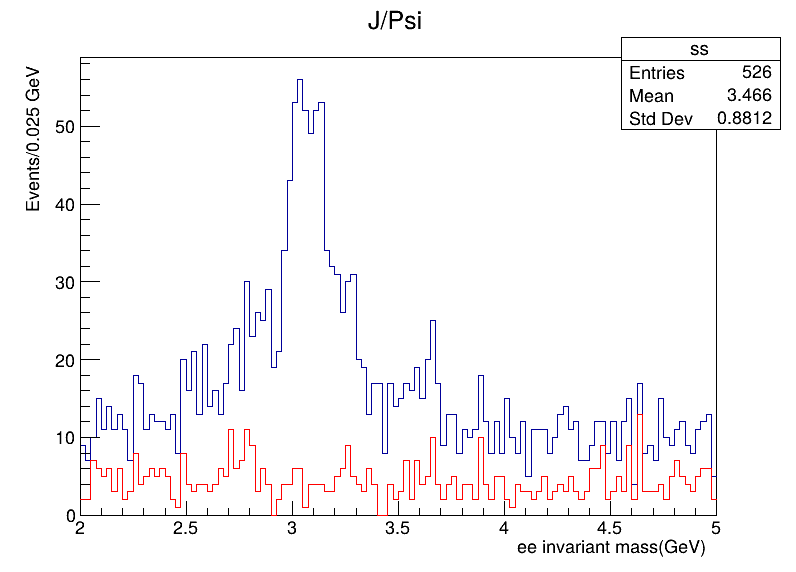

In [14]:
c=ROOT.TCanvas("c", "", 800, 600)
JPsi.SetMinimum(0)
JPsi.Draw()
ss.SetLineColor(ROOT.kRed)
ss.Draw("same")
c.Draw()

Warning in <TCanvas::Constructor>: Deleting canvas with same name: d


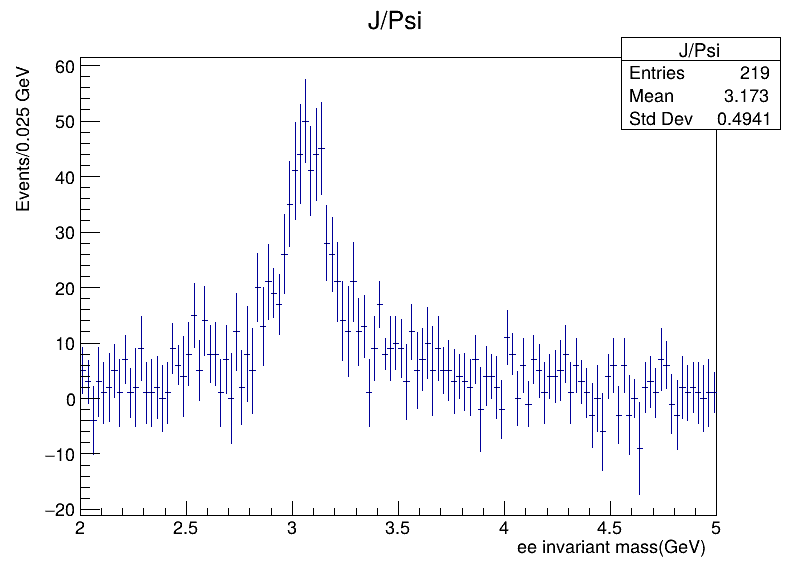

In [17]:
sub=JPsi.Clone()
c=ROOT.TCanvas("d", "", 800, 600)
sub.Add(ss, -2)
#sub.SetMinimum(0)

sub.Draw()
c.Draw()

In [18]:
sub.Integral()

948.0

Warning in <TCanvas::Constructor>: Deleting canvas with same name: d


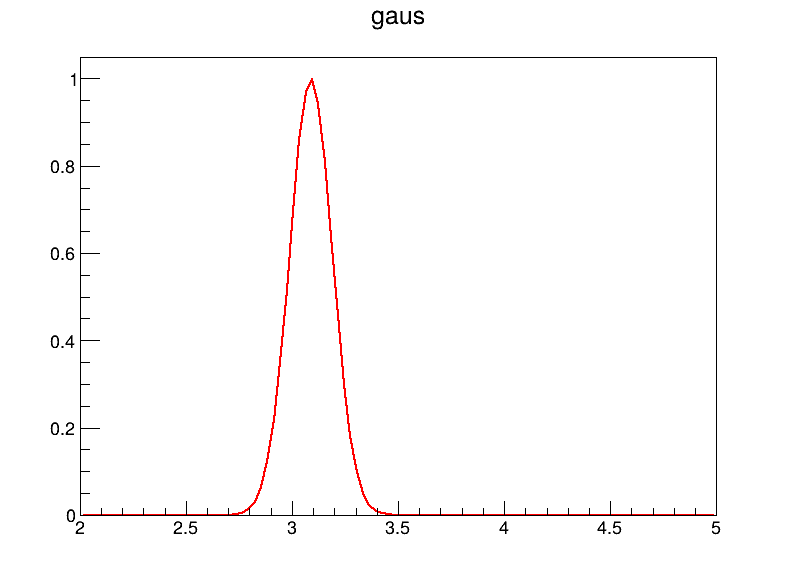

In [20]:
f=ROOT.TF1("f", "gaus", 2, 5)
f.SetParameter(0, 1)
f.SetParameter(1, 3.09)
f.SetParameter(2, 0.1)

c=ROOT.TCanvas("d", "", 800, 600)
f.Draw()
c.Draw()

In [21]:
sub.Fit(f)

****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      120.245
NDf                       =          117
Edm                       =  2.96978e-07
NCalls                    =           89
Constant                  =      30.2542   +/-   3.31566     
Mean                      =      3.08044   +/-   0.0171971   
Sigma                     =     0.240428   +/-   0.0347542    	 (limited)


Error in <TFitResultPtr>: TFitResult is empty - use the fit option S


Error in <TFitResultPtr>: TFitResult is empty - use the fit option S
Error in <TFitResultPtr>: TFitResult is empty - use the fit option S
Error in <TFitResultPtr>: TFitResult is empty - use the fit option S
Error in <TFitResultPtr>: TFitResult is empty - use the fit option S
Error in <TFitResultPtr>: TFitResult is empty - use the fit option S
Error in <TFitResultPtr>: TFitResult is empty - use the fit option S
Error in <TFitResultPtr>: TFitResult is empty - use the fit option S
Error in <TFitResultPtr>: TFitResult is empty - use the fit option S
Error in <TFitResultPtr>: TFitResult is empty - use the fit option S
Error in <TFitResultPtr>: TFitResult is empty - use the fit option S
Error in <TFitResultPtr>: TFitResult is empty - use the fit option S
Error in <TFitResultPtr>: TFitResult is empty - use the fit option S
Error in <TFitResultPtr>: TFitResult is empty - use the fit option S
Error in <TFitResultPtr>: TFitResult is empty - use the fit option S
Error in <TFitResultPtr>: TFitResu

Warning in <TCanvas::Constructor>: Deleting canvas with same name: d


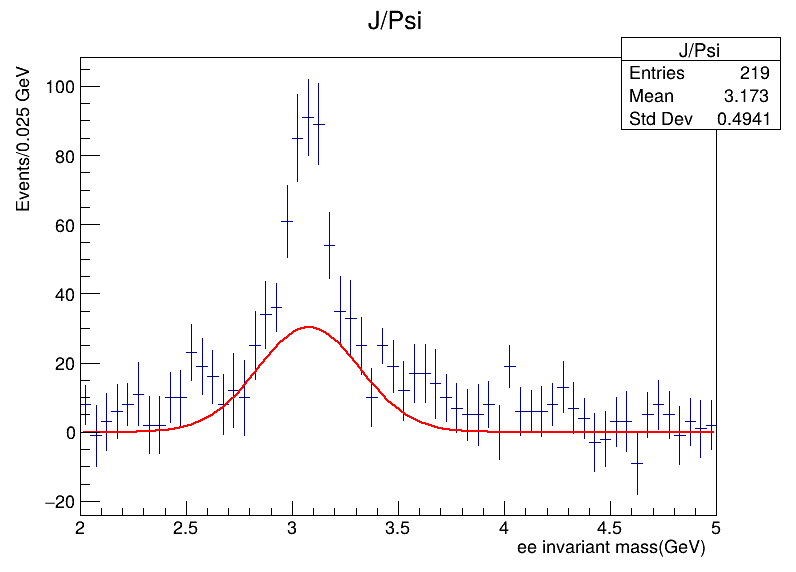

In [23]:
c=ROOT.TCanvas("d", "", 800, 600)
sub.Rebin(2)
sub.Draw()
c.Draw()

****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      150.692
NDf                       =          115
Edm                       =   2.5988e-08
NCalls                    =          618
p0                        =      33.3588   +/-   2.97353     
p1                        =      3.07584   +/-   0.0108415   
p2                        =     0.154075   +/-   0.0167883   
p3                        =      15.6817   +/-   1.51835     
p4                        =     -1.30437   +/-   0.382608    


Warning in <TCanvas::Constructor>: Deleting canvas with same name: d


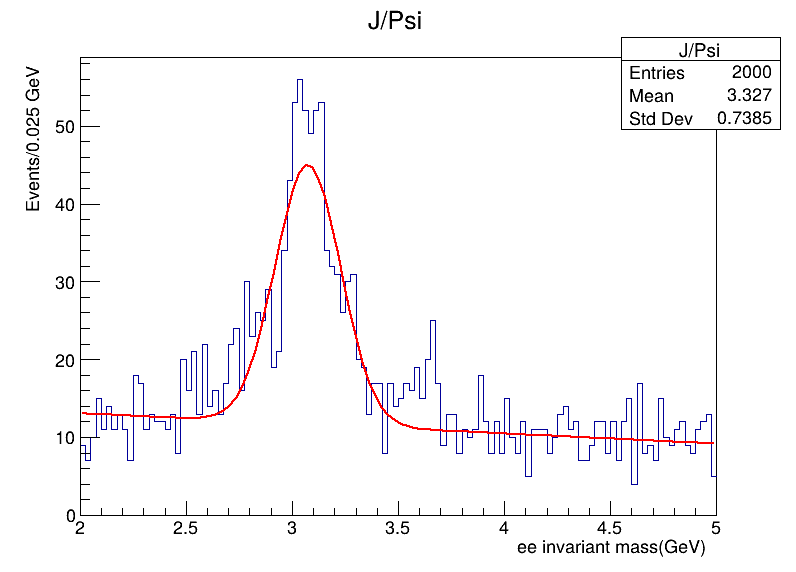

In [26]:
f2=ROOT.TF1("f2", "gaus(0)+pol1(3)", 2, 5)
#f2.SetParameter(0, 1)
#f2.SetParameter(1, 3.09)
#f2.SetParameter(2, 0.1)
f2.SetParameters(1, 3.09, 0.1, 0, 0)

JPsi.Fit(f2)
c=ROOT.TCanvas("d", "", 800, 600)
JPsi.Draw()
c.Draw()

In [28]:
f2.Integral(2,5)

46.232654315118815